<a href="https://colab.research.google.com/github/aakashkumar089/Class-notes/blob/main/OTS_XGBoost_mushroom_with_new_data_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XGBoost Demo — Mushroom Classification
Same dataset/preprocessing as the AdaBoost notebook, using **XGBoost** instead.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/mushrooms.csv")

In [ ]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [ ]:
df['class'].unique()

array(['p', 'e'], dtype=object)

## Preprocessing
XGBoost needs numeric features and a numeric target, so:
- One-hot encode the categorical features (`X`)
- Label-encode the target (`y`) — XGBoost's sklearn API can't take string labels like `'p'`/`'e'` directly

In [ ]:
X = df.drop('class', axis=1)
y = df['class']

X = pd.get_dummies(X, drop_first=True)
X = X.astype(int)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)   # 'e' -> 0, 'p' -> 1 (check le.classes_ to confirm)
le.classes_

array(['e', 'p'], dtype=object)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=101)

## Install & import XGBoost
(Uncomment the `pip install` line if xgboost isn't already available in your environment, e.g. fresh Colab runtime.)

In [ ]:
# !pip install xgboost

from xgboost import XGBClassifier

In [ ]:
model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    eval_metric='logloss',
    random_state=101
)

In [ ]:
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
# Evaluation

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [ ]:
predictions = model.predict(X_test)

In [ ]:
predictions

array([1, 0, 1, ..., 1, 1, 0])

In [ ]:
y_test

array([1, 0, 1, ..., 1, 1, 0])

In [ ]:
confusion_matrix(y_test, predictions)

array([[655,   0],
       [  0, 564]])

In [ ]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       655
           1       1.00      1.00      1.00       564

    accuracy                           1.00      1219
   macro avg       1.00      1.00      1.00      1219
weighted avg       1.00      1.00      1.00      1219



In [ ]:
accuracy_score(y_test, predictions)

1.0

## Feature importance

In [ ]:
model.feature_importances_.argmax()

np.int64(22)

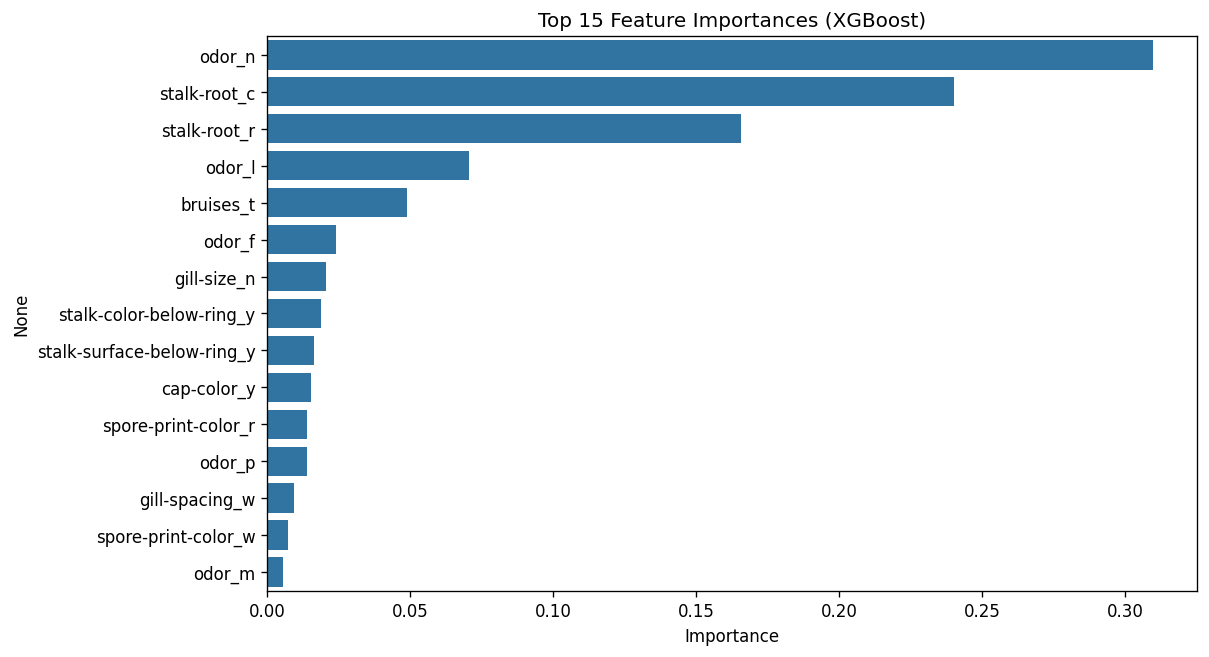

In [ ]:
feat_imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10,6), dpi=120)
sns.barplot(x=feat_imp.head(15).values, y=feat_imp.head(15).index)
plt.title('Top 15 Feature Importances (XGBoost)')
plt.xlabel('Importance')
plt.show()

## n_estimators vs error rate
Same sweep style as the AdaBoost notebook, so you can compare curves directly.

In [ ]:
error_rates = []

for n in range(1, 96):
    m = XGBClassifier(n_estimators=n, max_depth=3, learning_rate=0.1,
                       eval_metric='logloss', random_state=101)
    m.fit(X_train, y_train)
    preds = m.predict(X_test)
    err = 1 - accuracy_score(y_test, preds)
    error_rates.append(err)

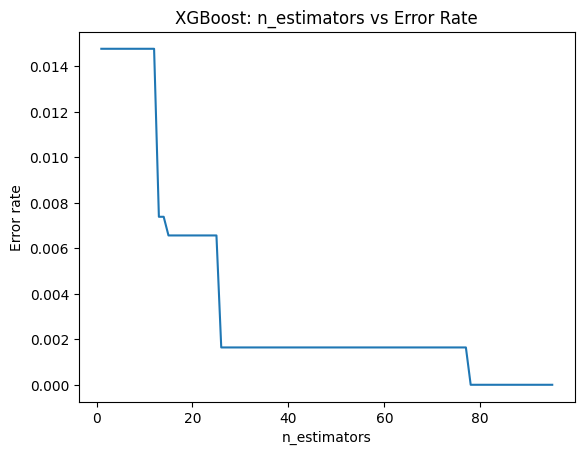

In [ ]:
plt.plot(range(1, 96), error_rates)
plt.xlabel('n_estimators')
plt.ylabel('Error rate')
plt.title('XGBoost: n_estimators vs Error Rate')
plt.show()

## Predict on new data

Everything above used rows from the same CSV. In real use you get **brand-new mushrooms** that were never in the file. The rule is simple:

> New data must go through **exactly the same preprocessing** as the training data, and end up with **exactly the same columns in the same order**.

Why this needs care: `pd.get_dummies(..., drop_first=True)` on one or two new rows would create a different set of columns (a single row only contains the categories it happens to have). So instead we one-hot encode the new rows and then **`reindex` to the training columns** (`X.columns`). Columns the new rows do not have become `0`; categories that training dropped (`drop_first`) are simply not needed.

The helper below also checks that the new data has the right columns and no category the model has never seen.

*For learning only: never eat a wild mushroom because a model said it is edible.*

In [ ]:
raw_features = df.drop('class', axis=1)          # original text columns (before one-hot encoding)
class_names = {'e': 'edible', 'p': 'poisonous'}


def prepare_new_data(new_df):
    # 1) same columns as the original data
    missing = [c for c in raw_features.columns if c not in new_df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    new_df = new_df[raw_features.columns]

    # 2) no category the model has never seen
    for col in raw_features.columns:
        unseen = set(new_df[col].dropna().unique()) - set(raw_features[col].unique())
        if unseen:
            raise ValueError(f"Column '{col}' has unseen value(s) {sorted(unseen)}. "
                             f"Allowed: {sorted(raw_features[col].unique())}")

    # 3) one-hot encode, then force the training columns (same names, same order)
    encoded = pd.get_dummies(new_df)
    encoded = encoded.reindex(columns=X.columns, fill_value=0)
    return encoded.astype(int)


def predict_mushrooms(new_df):
    Xn = prepare_new_data(new_df)
    pred = model.predict(Xn)                               # 0 / 1
    proba = model.predict_proba(Xn)                        # [P(class 0), P(class 1)]
    p_col = list(le.classes_).index('p')                   # which column is 'poisonous'

    out = new_df.reset_index(drop=True).copy()
    out['prediction'] = [class_names[c] for c in le.inverse_transform(pred)]
    out['prob_poisonous'] = proba[:, p_col]
    out['confidence'] = proba.max(axis=1)
    return out


print("Helper ready. Model classes:", dict(zip(range(len(le.classes_)), le.classes_)))

Helper ready. Model classes: {0: 'e', 1: 'p'}


### A. Rows the model has never seen (the test set), without their answer

We take 8 rows from the test set, **hide the `class` column** the way it would be hidden in real life, predict, and then compare with the true answer.

In [ ]:
sample_idx = X_test.index[:8]                                   # rows kept out of training
new_rows = df.loc[sample_idx].drop('class', axis=1)             # no answer given to the model
actual = df.loc[sample_idx, 'class'].map(class_names).values    # kept aside to check

result = predict_mushrooms(new_rows)
result['actual'] = actual
result['correct'] = result['prediction'] == result['actual']

show_cols = ['odor', 'spore-print-color', 'gill-size', 'prediction', 'prob_poisonous', 'confidence', 'actual', 'correct']
result[show_cols]

,odor,spore-print-color,gill-size,prediction,prob_poisonous,confidence,actual,correct
0,f,h,b,poisonous,0.999862,0.999862,poisonous,True
1,n,n,b,edible,0.000310,0.999690,edible,True
2,f,h,b,poisonous,0.999921,0.999921,poisonous,True
3,n,o,b,edible,0.001025,0.998975,edible,True
4,n,w,b,edible,0.001787,0.998213,edible,True
5,l,k,b,edible,0.002540,0.997460,edible,True
6,l,k,b,edible,0.002617,0.997383,edible,True
7,s,w,n,poisonous,0.997878,0.997878,poisonous,True


### B. Your own mushrooms: type the features and predict

`template` fills every feature with its most common value, and you override the ones you want to describe. To see the allowed values for any column, use `raw_features['odor'].unique()`.

Odor codes in this dataset: `a` almond, `l` anise, `c` creosote, `y` fishy, `f` foul, `m` musty, `n` none, `p` pungent, `s` spicy.

In [ ]:
template = raw_features.mode().iloc[0].to_dict()      # most common value of every feature

my_mushrooms = pd.DataFrame([
    {**template, 'odor': 'n'},                         # no smell
    {**template, 'odor': 'f'},                         # foul smell
    {**template, 'odor': 'a', 'bruises': 't'},         # almond smell, bruises
])

result_b = predict_mushrooms(my_mushrooms)
result_b[['odor', 'bruises', 'prediction', 'prob_poisonous', 'confidence']]

,odor,bruises,prediction,prob_poisonous,confidence
0,n,f,edible,0.002319,0.997681
1,f,f,poisonous,0.999765,0.999765
2,a,t,edible,0.138563,0.861437


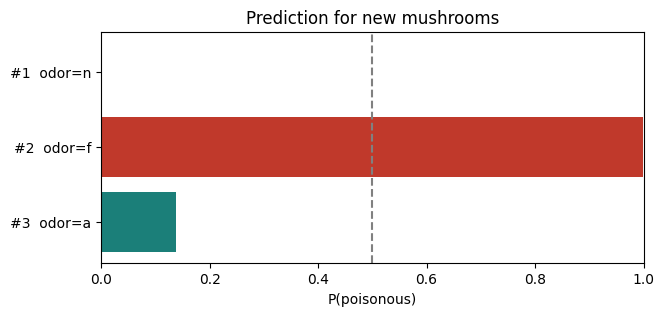

In [ ]:
# Probability of "poisonous" for the three typed mushrooms
labels = [f"#{i + 1}  odor={o}" for i, o in enumerate(result_b['odor'])]
colors = ['#C0392B' if p > 0.5 else '#1B7F79' for p in result_b['prob_poisonous']]
plt.figure(figsize=(7, 3))
plt.barh(labels, result_b['prob_poisonous'], color=colors)
plt.axvline(0.5, ls='--', color='gray')
plt.xlim(0, 1); plt.xlabel('P(poisonous)'); plt.title('Prediction for new mushrooms')
plt.gca().invert_yaxis(); plt.show()

### C. Why did the model say that? (per-feature contribution)

XGBoost can return how much each feature pushed one prediction toward "poisonous" (positive) or "edible" (negative), measured in log-odds. The contributions plus the bias add up to the model's raw score for that row.

Mushroom #2: predicted poisonous (P(poisonous) = 1.000)


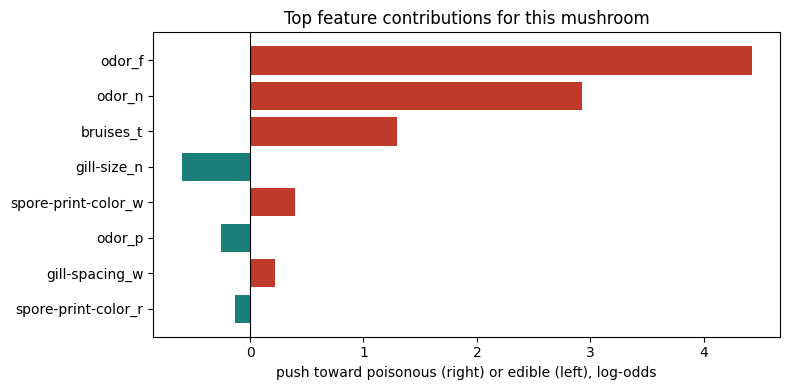

In [ ]:
from xgboost import DMatrix

row = 1                                                   # which new mushroom to explain (0, 1 or 2)
Xn = prepare_new_data(my_mushrooms)
contrib = model.get_booster().predict(DMatrix(Xn), pred_contribs=True)[row]   # last value is the bias
contrib = pd.Series(contrib[:-1], index=Xn.columns)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8)

print(f"Mushroom #{row + 1}: predicted {result_b.loc[row, 'prediction']} "
      f"(P(poisonous) = {result_b.loc[row, 'prob_poisonous']:.3f})")
plt.figure(figsize=(8, 4))
plt.barh(top.index, top.values, color=['#C0392B' if v > 0 else '#1B7F79' for v in top.values])
plt.axvline(0, color='black', lw=0.8)
plt.gca().invert_yaxis()
plt.xlabel('push toward poisonous (right) or edible (left), log-odds')
plt.title('Top feature contributions for this mushroom'); plt.tight_layout(); plt.show()

### D. A whole file of new mushrooms (save, load, predict)

In practice new data arrives as a CSV with the **same columns as `mushrooms.csv`, but without `class`**. This cell creates such a file from 5 test rows so it runs as is. To use your own file in Colab, upload it and set `NEW_CSV` to its name (or use the commented upload lines).

In [ ]:
NEW_CSV = "new_mushrooms.csv"

# Demo file: 5 test rows without the answer column. Skip this line if you upload your own file.
df.loc[X_test.index[8:13]].drop('class', axis=1).to_csv(NEW_CSV, index=False)

# --- To upload your own file in Colab, uncomment:
# from google.colab import files
# up = files.upload();  NEW_CSV = list(up.keys())[0]

new_data = pd.read_csv(NEW_CSV)
predictions_new = predict_mushrooms(new_data)
predictions_new[['odor', 'spore-print-color', 'prediction', 'prob_poisonous', 'confidence']]

,odor,spore-print-color,prediction,prob_poisonous,confidence
0,n,n,edible,0.000301,0.999699
1,n,k,edible,0.000789,0.999211
2,a,n,edible,0.003254,0.996746
3,s,w,poisonous,0.997878,0.997878
4,n,n,edible,0.000310,0.999690


In [ ]:
# Save the predictions and download them (Colab)
predictions_new.to_csv("mushroom_predictions.csv", index=False)
# from google.colab import files; files.download("mushroom_predictions.csv")
print("saved mushroom_predictions.csv with", len(predictions_new), "rows")

saved mushroom_predictions.csv with 5 rows


### Save the trained model so you can predict later without retraining

In [ ]:
model.save_model("mushroom_xgb.json")

from xgboost import XGBClassifier
loaded = XGBClassifier()
loaded.load_model("mushroom_xgb.json")

# The loaded model gives the same answers (it still needs the same prepared columns)
Xn = prepare_new_data(my_mushrooms)
print("same predictions after reload:", (loaded.predict(Xn) == model.predict(Xn)).all())

same predictions after reload: True
